# RIAWELC Weld Defect Pipeline
## ResNet50: Transfer Learning and Fine-Tuning on YOLO-Cropped Regions

**Input:** YOLO regions of interest and the weld-level partition produced by notebook `00_Data_Preparation_and_YOLO_known_weld.ipynb`.

**Training strategy:** ImageNet-pretrained `resnet50.a1_in1k` → classifier head trained with the backbone frozen → full network fine-tuning with discriminative learning rates, cosine schedule, label smoothing and class-balanced loss.

## 1. Environment Setup

### 1.1 Install Dependencies

In [1]:
!pip -q install timm

### 1.2 Import Libraries

In [2]:
import os, json, math, time, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix, roc_auc_score, roc_curve,
                             cohen_kappa_score, matthews_corrcoef)
from sklearn.preprocessing import label_binarize

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import timm

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

c:\Users\dipkh\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1.3 Experiment Configuration

`PROTOCOL` selects the evaluation setting:

| Value | Meaning |
|---|---|
| `"weld_holdout"` | Primary protocol. Train, validation and test welds are disjoint (methodology requirement 1). |
| `"known_weld"` | Secondary protocol. Official RIAWELC split after duplicate removal; test patches come from welds and radiographs seen in training. |

In [3]:
MODEL_KEY   = "ResNet50"
TIMM_NAME   = "resnet50.a1_in1k"
PROJECT_DIR = Path(r"C:\Users\dipkh\Downloads\RIAWLC\3")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT_DIR)
OUTPUT_ROOT = PROJECT_DIR / "riawelc_outputs"
PROTOCOL    = "known_weld"

IMG_SIZE        = 224
BATCH_SIZE      = 64
EPOCHS          = 30
FREEZE_EPOCHS   = 2
WARMUP_EPOCHS   = 2
LR_HEAD         = 1e-3
LR_BACKBONE     = 1e-4
WEIGHT_DECAY    = 0.05
LABEL_SMOOTHING = 0.1
PATIENCE        = 7
INTENSITY_NORM  = True
STRONG_AUG      = True
USE_TTA         = True
N_BOOTSTRAP     = 1000
SEED            = 42
NUM_WORKERS     = 0 if os.name == "nt" else min(8, os.cpu_count() or 2)

SHARED  = OUTPUT_ROOT / PROTOCOL / "_shared"
OUT_DIR = OUTPUT_ROOT / PROTOCOL / MODEL_KEY
assert (SHARED / "manifest.csv").exists(), f"Run notebook 00 with PROTOCOL='{PROTOCOL}' first"
for d in [OUT_DIR / "figures", SHARED / "predictions"]:
    d.mkdir(parents=True, exist_ok=True)

DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
torch.backends.cudnn.benchmark = False

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything()
print(f"Model: {MODEL_KEY} ({TIMM_NAME}) | Protocol: {PROTOCOL} | Device: {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if USE_AMP else ""))

Model: ResNet50 (resnet50.a1_in1k) | Protocol: known_weld | Device: cuda (NVIDIA GeForce RTX 3050 6GB Laptop GPU)


## 2. Load the Prepared Dataset

### 2.1 Manifest and Class Definitions

In [4]:
config = json.loads((SHARED / "config.json").read_text())
assert config["protocol"] == PROTOCOL
CLASS_ORDER = config["class_order"]
NAMES = [config["display_names"][k] for k in CLASS_ORDER]
SHORT = [config["short_names"][k] for k in CLASS_ORDER]
NUM_CLASSES = len(CLASS_ORDER)
df = pd.read_csv(SHARED / "manifest.csv")
train_df, val_df, test_df = (df[df.split == s].reset_index(drop=True) for s in ["train", "val", "test"])
print(f"Annotation: {config['annotation']} | YOLO validation mAP50: {config['yolo_val_metrics']['mAP50']:.4f}")
display(pd.crosstab(df.split, df.class_name, margins=True).reindex(["train", "val", "test", "All"]))

Annotation: automatic weak boxes | YOLO validation mAP50: 0.8398


class_name,Crack,Lack of Penetration,No Defect,Porosity,All
split,,,,,
train,4197,2447,3300,3476,13420
val,1908,1113,1500,1580,6101
test,765,446,600,632,2443
All,6870,4006,5400,5688,21964


### 2.2 Partition Integrity Check

In [5]:
for lvl in ["md5", "radiograph", "weld"]:
    shared_tt = len(set(train_df[lvl]) & set(test_df[lvl]))
    print(f"{lvl:>10}: shared between train and test = {shared_tt}")
assert not set(train_df.md5) & set(test_df.md5)
if PROTOCOL == "weld_holdout":
    assert not set(train_df.weld) & set(test_df.weld) and not set(val_df.weld) & set(test_df.weld)
    print("Weld-disjoint partition confirmed.")

       md5: shared between train and test = 0
radiograph: shared between train and test = 108
      weld: shared between train and test = 28


## 3. Preprocessing, Augmentation and Data Loaders

In [6]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

class PercentileStretch:
    def __call__(self, img):
        a = np.asarray(img, dtype=np.float32)
        lo, hi = np.percentile(a, 1), np.percentile(a, 99)
        return Image.fromarray((np.clip((a - lo) / max(hi - lo, 1.0), 0, 1) * 255).astype(np.uint8))

class RandomGamma:
    def __init__(self, lo=0.6, hi=1.6, p=0.7): self.lo, self.hi, self.p = lo, hi, p
    def __call__(self, img):
        if random.random() > self.p: return img
        g = math.exp(random.uniform(math.log(self.lo), math.log(self.hi)))
        return Image.fromarray(((np.asarray(img, dtype=np.float32) / 255.0) ** g * 255).astype(np.uint8))

class AddGaussianNoise:
    def __init__(self, std=(0.0, 0.05), p=0.4): self.std, self.p = std, p
    def __call__(self, t):
        return t if random.random() > self.p else t + torch.randn_like(t) * random.uniform(*self.std)

class ToThreeChannels:
    def __call__(self, t):
        return t.repeat(3, 1, 1) if t.shape[0] == 1 else t

pre   = [PercentileStretch()] if INTENSITY_NORM else []
inten = [RandomGamma(), T.RandomApply([T.GaussianBlur(5, sigma=(0.1, 1.5))], p=0.3)] if STRONG_AUG else []
noise = [AddGaussianNoise()] if STRONG_AUG else []

train_tfm = T.Compose(pre + inten + [
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.3, contrast=0.3) if STRONG_AUG else T.ColorJitter(0.2, 0.2),
    T.ToTensor(), *noise, ToThreeChannels(), T.Normalize(MEAN, STD)])
eval_tfm = T.Compose(pre + [T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), ToThreeChannels(), T.Normalize(MEAN, STD)])

class WeldDataset(Dataset):
    def __init__(self, frame, tfm):
        self.paths, self.labels, self.tfm = frame.cls_path.tolist(), frame.label.tolist(), tfm
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return self.tfm(Image.open(self.paths[i]).convert("L")), self.labels[i]

loader_kw = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=USE_AMP, persistent_workers=NUM_WORKERS > 0)
train_loader = DataLoader(WeldDataset(train_df, train_tfm), shuffle=True, drop_last=True,
                          generator=torch.Generator().manual_seed(SEED), **loader_kw)
val_loader  = DataLoader(WeldDataset(val_df, eval_tfm), shuffle=False, **loader_kw)
test_loader = DataLoader(WeldDataset(test_df, eval_tfm), shuffle=False, **loader_kw)

counts = np.bincount(train_df.label, minlength=NUM_CLASSES).clip(min=1)
class_w = torch.tensor((counts.sum() / (NUM_CLASSES * counts)) ** 0.5, dtype=torch.float32, device=DEVICE)
x0, _ = train_loader.dataset[0]
print(f"Train {len(train_df):,} | Val {len(val_df):,} | Test {len(test_df):,} | input tensor {tuple(x0.shape)}")
print("Class weights:", dict(zip(SHORT, class_w.cpu().numpy().round(3))))

Train 13,420 | Val 6,101 | Test 2,443 | input tensor (3, 224, 224)
Class weights: {'LP': np.float32(1.171), 'CR': np.float32(0.894), 'PO': np.float32(0.982), 'ND': np.float32(1.008)}


## 4. Model Architecture and Training Routine

In [7]:
def build_model(pretrained=True):
    return timm.create_model(TIMM_NAME, pretrained=pretrained, num_classes=NUM_CLASSES, drop_rate=0.2, drop_path_rate=0.1)

def run_epoch(model, loader, criterion, optimizer=None, scheduler=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    tot, n, ys, ps = 0.0, 0, [], []
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.set_grad_enabled(train), torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(x)
            loss = criterion(logits, y)
        if train:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
        tot += loss.item() * x.size(0); n += x.size(0)
        ys.append(y.cpu()); ps.append(logits.argmax(1).cpu())
    y, p = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return tot / n, accuracy_score(y, p), f1_score(y, p, average="macro")

def fit():
    seed_everything()
    model = build_model().to(DEVICE)
    head = list(model.get_classifier().parameters())
    head_ids = {id(p) for p in head}
    backbone = [p for p in model.parameters() if id(p) not in head_ids]
    opt = torch.optim.AdamW([{"params": backbone, "lr": LR_BACKBONE}, {"params": head, "lr": LR_HEAD}],
                            weight_decay=WEIGHT_DECAY)
    spe = len(train_loader); total, warm = EPOCHS * spe, WARMUP_EPOCHS * spe
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler = (torch.amp.GradScaler("cuda", enabled=USE_AMP) if hasattr(torch.amp, "GradScaler")
              else torch.cuda.amp.GradScaler(enabled=USE_AMP))
    crit = nn.CrossEntropyLoss(weight=class_w, label_smoothing=LABEL_SMOOTHING)
    ckpt = OUT_DIR / f"{MODEL_KEY}_best.pt"
    best_f1, best_loss, bad, hist = -1.0, np.inf, 0, []
    for ep in range(EPOCHS):
        frozen = ep < FREEZE_EPOCHS
        for p in backbone:
            p.requires_grad = not frozen
        t0 = time.time()
        tr = run_epoch(model, train_loader, crit, opt, sched, scaler)
        va = run_epoch(model, val_loader, crit)
        hist.append(dict(epoch=ep + 1, train_loss=tr[0], train_acc=tr[1], train_f1=tr[2],
                         val_loss=va[0], val_acc=va[1], val_f1=va[2]))
        improved = va[2] > best_f1 + 1e-4 or (abs(va[2] - best_f1) <= 1e-4 and va[0] < best_loss)
        if improved:
            best_f1, best_loss, bad = va[2], va[0], 0
            torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
        print(f"Epoch {ep+1:02d}{' [head]' if frozen else '       '} | train loss {tr[0]:.4f} acc {tr[1]:.4f} "
              f"| val loss {va[0]:.4f} acc {va[1]:.4f} F1 {va[2]:.4f}{'  ✓' if improved else ''} | {time.time()-t0:.0f}s")
        if not frozen and bad >= PATIENCE:
            print("Early stopping."); break
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return model, pd.DataFrame(hist)

@torch.no_grad()
def predict(model, loader, tta=USE_TTA):
    model.eval(); out = []
    for x, _ in loader:
        x = x.to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            views = [x, torch.flip(x, [3]), torch.flip(x, [2])] if tta else [x]
            out.append(torch.stack([model(v).float().softmax(1) for v in views]).mean(0).cpu())
    return torch.cat(out).numpy()

## 5. Model Training and Learning Curves

Epoch 01 [head] | train loss 1.3046 acc 0.4455 | val loss 1.1936 acc 0.5273 F1 0.4718  ✓ | 709s
Epoch 02 [head] | train loss 1.0798 acc 0.6494 | val loss 1.0308 acc 0.6109 F1 0.5937  ✓ | 334s
Epoch 03        | train loss 0.7531 acc 0.8113 | val loss 0.5431 acc 0.9243 F1 0.9196  ✓ | 324s
Epoch 04        | train loss 0.5494 acc 0.9150 | val loss 0.4509 acc 0.9613 F1 0.9588  ✓ | 391s
Epoch 05        | train loss 0.4908 acc 0.9394 | val loss 0.4227 acc 0.9730 F1 0.9716  ✓ | 444s
Epoch 06        | train loss 0.4636 acc 0.9531 | val loss 0.4085 acc 0.9779 F1 0.9765  ✓ | 443s
Epoch 07        | train loss 0.4419 acc 0.9631 | val loss 0.4006 acc 0.9833 F1 0.9823  ✓ | 432s
Epoch 08        | train loss 0.4328 acc 0.9676 | val loss 0.3957 acc 0.9825 F1 0.9814 | 430s
Epoch 09        | train loss 0.4253 acc 0.9712 | val loss 0.3893 acc 0.9867 F1 0.9860  ✓ | 345s
Epoch 10        | train loss 0.4151 acc 0.9747 | val loss 0.3922 acc 0.9856 F1 0.9848 | 403s
Epoch 11        | train loss 0.4165 acc 0.9746

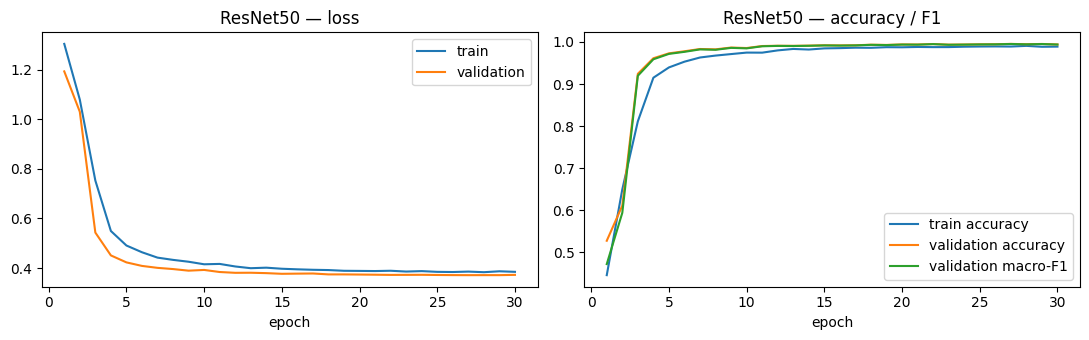

In [8]:
model, history = fit()
history.to_csv(OUT_DIR / "history.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history.epoch, history.train_loss, label="train"); ax[0].plot(history.epoch, history.val_loss, label="validation")
ax[0].set_title(f"{MODEL_KEY}: loss")
ax[1].plot(history.epoch, history.train_acc, label="train accuracy"); ax[1].plot(history.epoch, history.val_acc, label="validation accuracy")
ax[1].plot(history.epoch, history.val_f1, label="validation macro-F1"); ax[1].set_title(f"{MODEL_KEY}: accuracy / F1")
for a in ax: a.legend(); a.set_xlabel("epoch")
plt.tight_layout(); plt.savefig(OUT_DIR / "figures/learning_curves.png", dpi=150); plt.show()

## 6. Evaluation Utilities

In [9]:
def compute_metrics(y, prob):
    pred = prob.argmax(1)
    P, R, F1, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    _, _, F1w, _ = precision_recall_fscore_support(y, pred, average="weighted", zero_division=0)
    try:
        auc = roc_auc_score(label_binarize(y, classes=range(NUM_CLASSES)), prob, average="macro")
    except ValueError:
        auc = np.nan
    return dict(accuracy=accuracy_score(y, pred), balanced_accuracy=balanced_accuracy_score(y, pred),
                precision_macro=P, recall_macro=R, f1_macro=F1, f1_weighted=F1w, roc_auc_macro=auc,
                cohen_kappa=cohen_kappa_score(y, pred), mcc=matthews_corrcoef(y, pred))

def bootstrap_ci(y, prob, n=N_BOOTSTRAP):
    rng = np.random.default_rng(SEED); pred = prob.argmax(1); acc, f1 = [], []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        acc.append(accuracy_score(y[i], pred[i])); f1.append(f1_score(y[i], pred[i], average="macro"))
    return np.percentile(acc, [2.5, 97.5]), np.percentile(f1, [2.5, 97.5])

def per_class_table(y, prob):
    rep = classification_report(y, prob.argmax(1), labels=range(NUM_CLASSES), target_names=NAMES,
                                output_dict=True, zero_division=0)
    t = pd.DataFrame(rep).T.loc[NAMES, ["precision", "recall", "f1-score", "support"]]
    yb = label_binarize(y, classes=range(NUM_CLASSES))
    t["roc_auc"] = [roc_auc_score(yb[:, k], prob[:, k]) if 0 < yb[:, k].sum() < len(yb) else np.nan for k in range(NUM_CLASSES)]
    return t

def plot_confusion(y, prob, title, fname):
    cm = confusion_matrix(y, prob.argmax(1), labels=range(NUM_CLASSES))
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, m, fmt, t in [(axes[0], cm, "d", "counts"), (axes[1], cmn, ".3f", "row-normalised")]:
        ax.imshow(m, cmap="Blues")
        for i in range(NUM_CLASSES):
            for j in range(NUM_CLASSES):
                ax.text(j, i, format(m[i, j], fmt), ha="center", va="center",
                        color="white" if m[i, j] > m.max() / 2 else "black")
        ax.set_xticks(range(NUM_CLASSES), SHORT); ax.set_yticks(range(NUM_CLASSES), SHORT)
        ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"{title} ({t})")
    plt.tight_layout(); plt.savefig(fname, dpi=200); plt.show()

def plot_roc(y, prob, title, fname):
    yb = label_binarize(y, classes=range(NUM_CLASSES))
    plt.figure(figsize=(6, 5))
    for k in range(NUM_CLASSES):
        if 0 < yb[:, k].sum() < len(yb):
            fpr, tpr, _ = roc_curve(yb[:, k], prob[:, k])
            plt.plot(fpr, tpr, label=f"{NAMES[k]} (AUC = {roc_auc_score(yb[:, k], prob[:, k]):.4f})")
    plt.plot([0, 1], [0, 1], "k--", lw=0.8); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
    plt.title(title); plt.legend(fontsize=8); plt.tight_layout(); plt.savefig(fname, dpi=200); plt.show()

## 7. Test-Set Results

### 7.1 Overall Performance

In [10]:
y_test = test_df.label.values
test_prob = predict(model, test_loader)
metrics = compute_metrics(y_test, test_prob)
(a_lo, a_hi), (f_lo, f_hi) = bootstrap_ci(y_test, test_prob)
results = pd.DataFrame([metrics], index=[MODEL_KEY]).round(4)
results["accuracy_95ci"] = f"[{a_lo:.4f}, {a_hi:.4f}]"
results["f1_macro_95ci"] = f"[{f_lo:.4f}, {f_hi:.4f}]"
results.to_csv(OUT_DIR / "test_results.csv")
np.savez(SHARED / "predictions" / f"{MODEL_KEY}.npz", prob=test_prob, y=y_test, path=test_df.path.values)
print(f"{MODEL_KEY} | protocol: {PROTOCOL} | test images: {len(y_test):,} | test welds: {test_df.weld.nunique()}")
display(results)

ResNet50 | protocol: known_weld | test images: 2,443 | test welds: 28


,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_macro,cohen_kappa,mcc,accuracy_95ci,f1_macro_95ci
ResNet50,0.9926,0.9926,0.9918,0.9926,0.9922,0.9926,0.9999,0.9901,0.9901,"[0.9894, 0.9955]","[0.9888, 0.9953]"


### 7.2 Per-Class Performance

In [11]:
pc = per_class_table(y_test, test_prob)
pc.to_csv(OUT_DIR / "per_class.csv")
display(pc.round(4))

,precision,recall,f1-score,support,roc_auc
Lack of Penetration,0.9866,0.9910,0.9888,446.0,0.9999
Crack,0.9987,0.9922,0.9954,765.0,1.0000
Porosity,0.9952,0.9921,0.9937,632.0,0.9999
No Defect,0.9868,0.9950,0.9909,600.0,0.9999


### 7.3 Confusion Matrix and ROC Curves

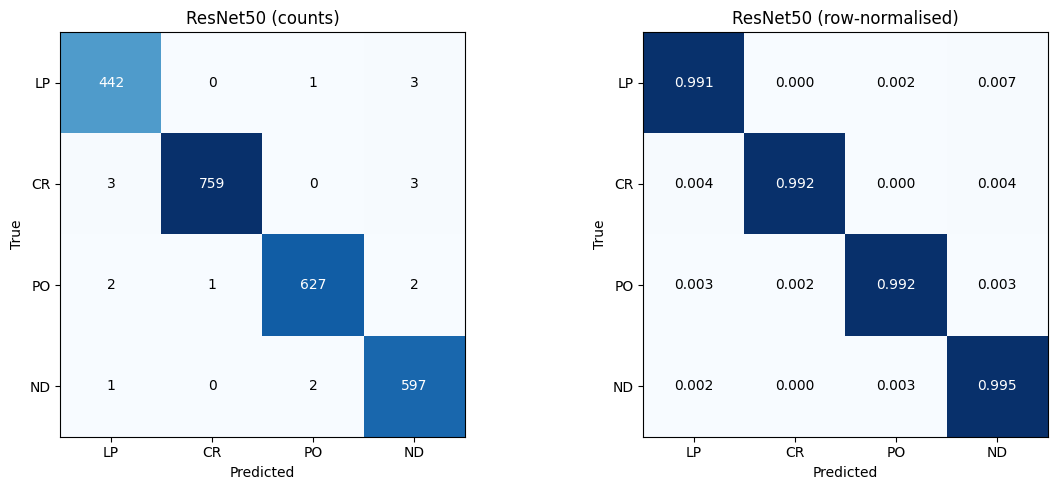

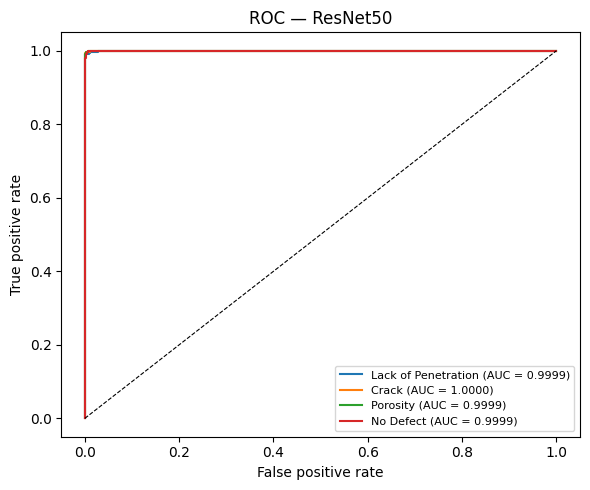

In [12]:
plot_confusion(y_test, test_prob, MODEL_KEY, OUT_DIR / "figures/confusion_matrix.png")
plot_roc(y_test, test_prob, f"ROC: {MODEL_KEY}", OUT_DIR / "figures/roc_curves.png")

### 7.4 Per-Weld and Detection-Status Breakdown

In [13]:
t = test_df.assign(correct=test_prob.argmax(1) == y_test)
by_weld = (t.groupby(["weld", "class_name"]).correct.agg(accuracy="mean", n="size").reset_index()
           .assign(errors=lambda d: ((1 - d.accuracy) * d.n).round().astype(int))
           .sort_values("errors", ascending=False))
by_weld.to_csv(OUT_DIR / "per_weld.csv", index=False)
display(by_weld.head(10).round(4))
display(t.groupby(["class_name", "has_detection"]).correct.agg(accuracy="mean", n="size").round(4))

,weld,class_name,accuracy,n,errors
49,RRT-88R,Crack,0.9726,73,2
19,RRT-22R,Crack,0.9310,29,2
50,RRT-88R,No Defect,0.9167,12,1
51,RRT-88R,Porosity,0.9524,21,1
32,RRT-28R,Porosity,0.9730,37,1
5,RRT-102R,Porosity,0.9231,13,1
27,RRT-26R,Porosity,0.9828,58,1
23,RRT-24R,Lack of Penetration,0.9667,30,1
18,RRT-20R,No Defect,0.8333,6,1
33,RRT-29R,Lack of Penetration,0.8571,7,1


accuracy    n
class_name          has_detection               
Crack               False            0.9892   93
                    True             0.9926  672
Lack of Penetration False            1.0000   70
                    True             0.9894  376
No Defect           False            0.9983  593
                    True             0.7143    7
Porosity            False            0.9474   19
                    True             0.9935  613

## 8. Explainability with Grad-CAM

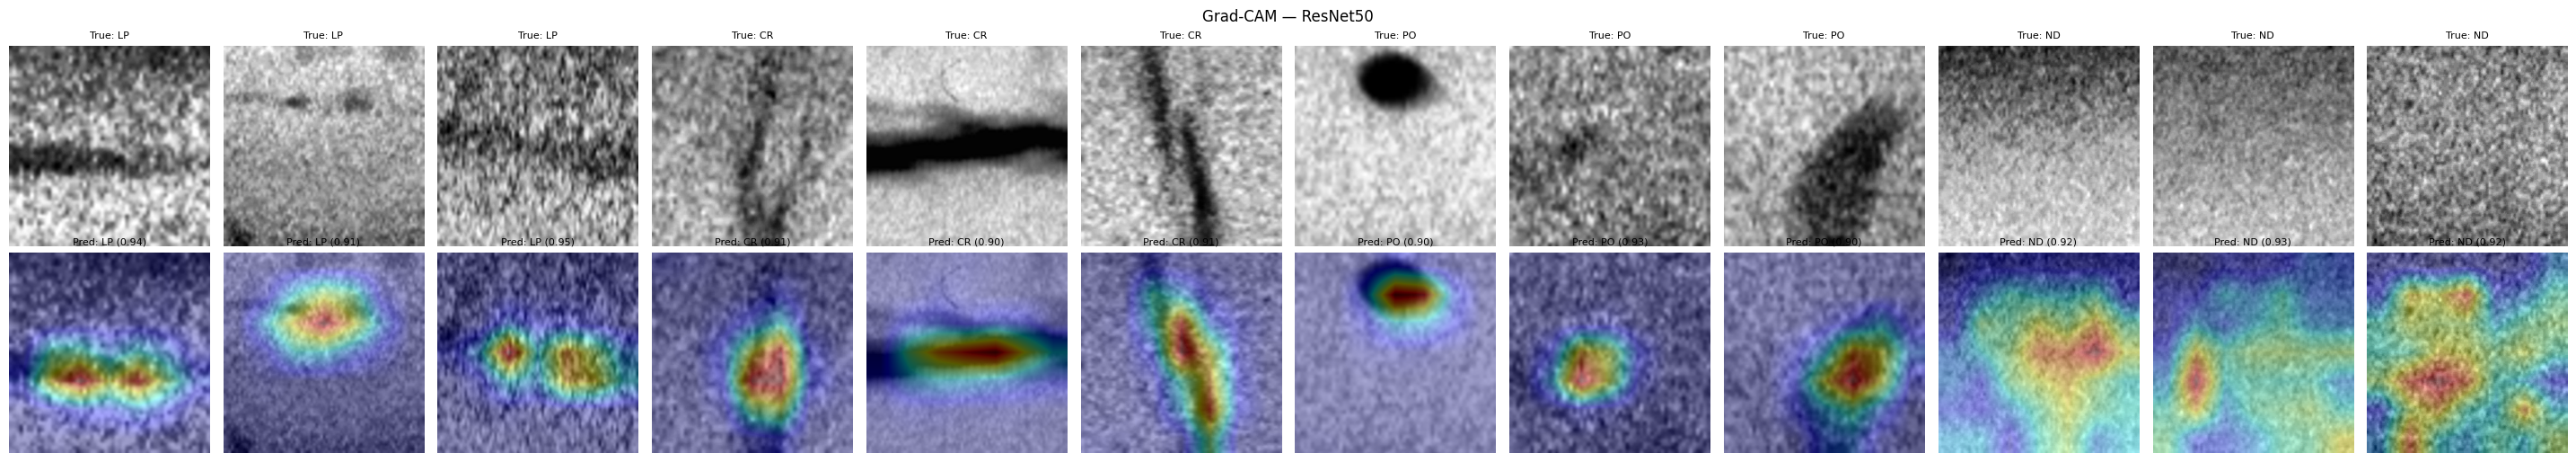

In [14]:
def gradcam(model, x):
    model.eval()
    with torch.enable_grad():
        feats = model.forward_features(x)
        feats.retain_grad()
        logits = model.forward_head(feats)
        model.zero_grad(set_to_none=True)
        logits.gather(1, logits.argmax(1).view(-1, 1)).sum().backward()
        cam = F.relu((feats.grad.mean((2, 3), keepdim=True) * feats).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
        lo, hi = cam.amin((1, 2), keepdim=True), cam.amax((1, 2), keepdim=True)
        cam = (cam - lo) / (hi - lo + 1e-8)
    return cam.detach().cpu().numpy(), logits.softmax(1).detach().cpu().numpy()

n_show = 3
picks = pd.concat([test_df[test_df.label == k].sample(min(n_show, (test_df.label == k).sum()), random_state=SEED)
                   for k in range(NUM_CLASSES)])
xb = torch.stack([eval_tfm(Image.open(p).convert("L")) for p in picks.cls_path]).to(DEVICE)
cams, probs = gradcam(model, xb)
fig, axes = plt.subplots(2, len(picks), figsize=(2.4 * len(picks), 5.2), squeeze=False)
for k in range(len(picks)):
    raw = np.array(Image.open(picks.cls_path.iloc[k]).convert("L").resize((IMG_SIZE, IMG_SIZE)))
    axes[0, k].imshow(raw, cmap="gray"); axes[0, k].set_title(f"True: {SHORT[picks.label.iloc[k]]}", fontsize=8)
    axes[1, k].imshow(raw, cmap="gray"); axes[1, k].imshow(cams[k], cmap="jet", alpha=0.35)
    axes[1, k].set_title(f"Pred: {SHORT[probs[k].argmax()]} ({probs[k].max():.2f})", fontsize=8)
    for a in axes[:, k]: a.axis("off")
plt.suptitle(f"Grad-CAM: {MODEL_KEY}"); plt.tight_layout()
plt.savefig(OUT_DIR / "figures/gradcam.png", dpi=200); plt.show()

## 9. Misclassification Analysis

Misclassified: 18 of 2,443


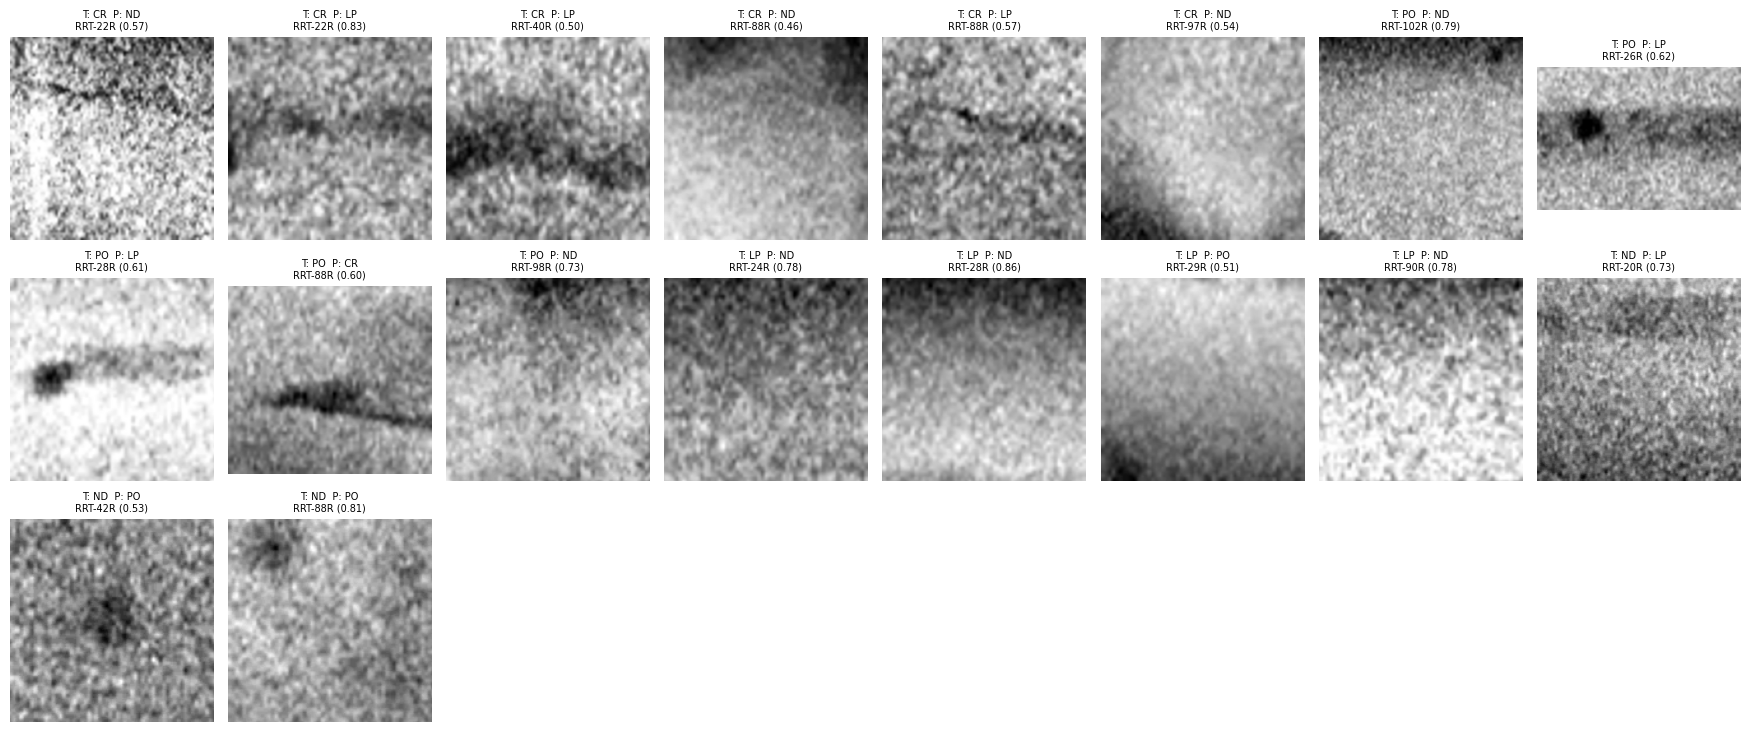

In [15]:
wrong = np.where(test_prob.argmax(1) != y_test)[0]
print(f"Misclassified: {len(wrong)} of {len(y_test):,}")
show = wrong[:24]
if len(show):
    cols = 8; rows = math.ceil(len(show) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(2.2 * cols, 2.5 * rows), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, i in zip(axes.ravel(), show):
        ax.imshow(Image.open(test_df.cls_path.iloc[i]).convert("L"), cmap="gray")
        ax.set_title(f"T: {SHORT[y_test[i]]}  P: {SHORT[test_prob[i].argmax()]}\n{test_df.weld.iloc[i]} ({test_prob[i].max():.2f})", fontsize=7)
    plt.tight_layout(); plt.savefig(OUT_DIR / "figures/misclassified.png", dpi=150); plt.show()

## 10. Experiment Summary Export

In [16]:
summary = dict(model=MODEL_KEY, timm_name=TIMM_NAME, protocol=PROTOCOL, annotation=config["annotation"],
               n_train=len(train_df), n_val=len(val_df), n_test=len(test_df), test_welds=config["test_welds"],
               img_size=IMG_SIZE, epochs_run=len(history), best_epoch=int(history.val_f1.idxmax() + 1),
               intensity_norm=INTENSITY_NORM, strong_aug=STRONG_AUG, tta=USE_TTA,
               test_metrics={k: round(float(v), 5) for k, v in metrics.items()})
(OUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
print("Saved to", OUT_DIR.resolve())

Saved to C:\Users\dipkh\Downloads\RIAWLC\3\riawelc_outputs\known_weld\ResNet50
